John George 
LOBO | SVC-rbf | SHAP 

In [1]:

import numpy as np
import pandas as pd
from collections import defaultdict
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import roc_auc_score, accuracy_score, balanced_accuracy_score
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (roc_auc_score, accuracy_score,
                              balanced_accuracy_score, confusion_matrix)
 

In [2]:
df = pd.read_csv("VST_batch_corrected_samples_x_genes_class_batch_090226.tsv", sep = '\t',index_col=0)
print (df.shape)
#print (df.head)

y = df['class']
batch = df['batch']
X = df.drop(columns=['class', 'batch'])
gene_cols = np.array(X.columns)


(218, 18835)


Batch 1: n_train=194, n_test=24, AUC=0.722, Acc=0.625, BalAcc=0.625
Confusion matrix for batch 1 (rows = actual, columns = predicted):
[[ 3  9]
 [ 0 12]]

Batch 2: n_train=182, n_test=36, AUC=0.579, Acc=0.528, BalAcc=0.513
Confusion matrix for batch 2 (rows = actual, columns = predicted):
[[ 6  7]
 [10 13]]

Batch 3: n_train=115, n_test=103, AUC=0.580, Acc=0.534, BalAcc=0.533
Confusion matrix for batch 3 (rows = actual, columns = predicted):
[[24 27]
 [21 31]]

Batch 4: n_train=202, n_test=16, AUC=0.836, Acc=0.875, BalAcc=0.855
Confusion matrix for batch 4 (rows = actual, columns = predicted):
[[ 4  1]
 [ 1 10]]

Batch 5: n_train=192, n_test=26, AUC=0.817, Acc=0.769, BalAcc=0.745
Confusion matrix for batch 5 (rows = actual, columns = predicted):
[[ 6  3]
 [ 3 14]]

Batch 6: n_train=205, n_test=13, AUC=0.452, Acc=0.538, BalAcc=0.500
Confusion matrix for batch 6 (rows = actual, columns = predicted):
[[0 6]
 [0 7]]

Per-fold results:
    held_out_batch  n_train  n_test       auc  accuracy

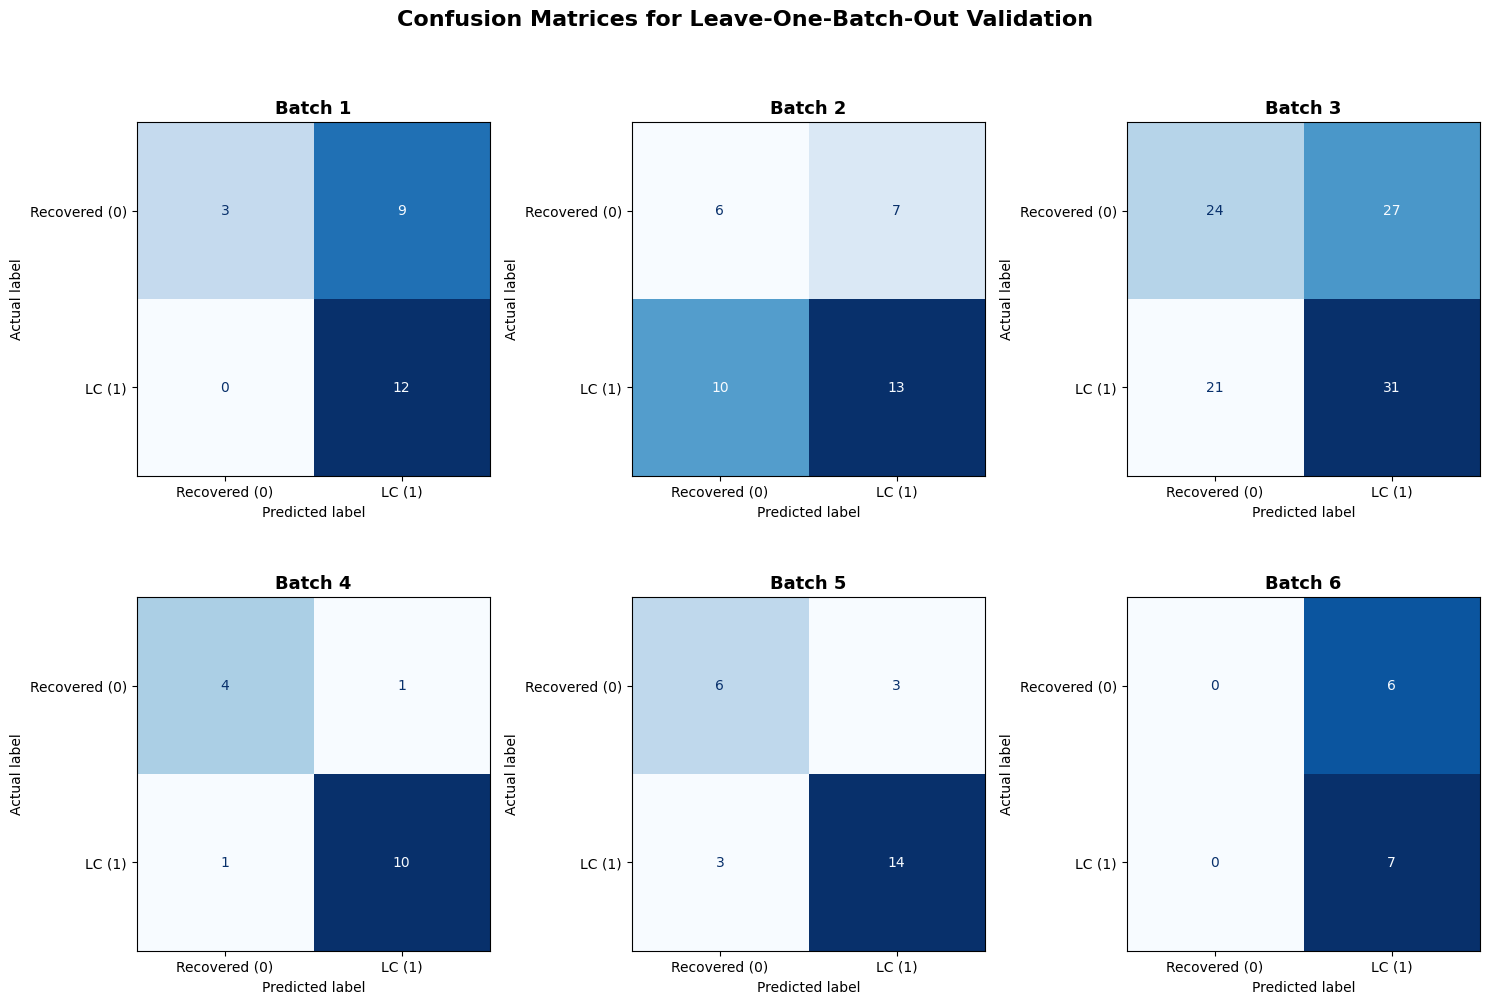

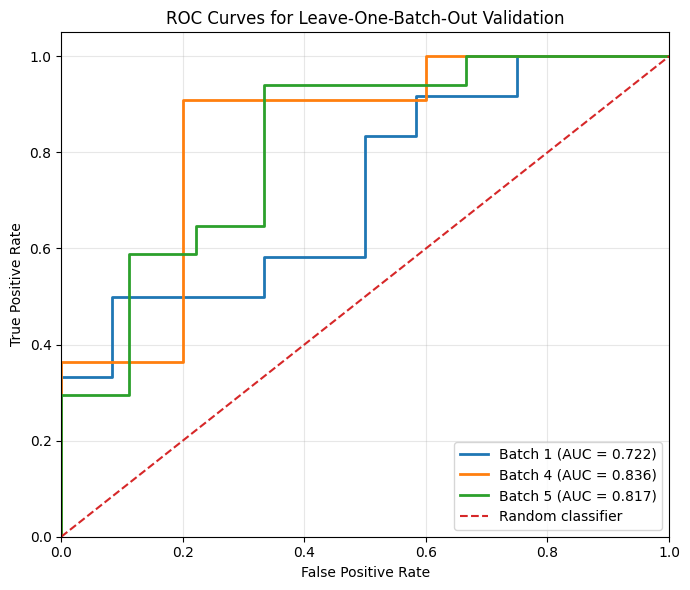

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_curve,
    ConfusionMatrixDisplay
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

batches = sorted(batch.unique())

fold_results = []

# Store ROC information for batches 1, 4 and 5
roc_data = {}

# Store confusion matrices for all batches
confusion_matrices = {}


# =============================================================
# LEAVE-ONE-BATCH-OUT VALIDATION
# =============================================================

for b in batches:

    train_mask = batch != b
    test_mask = batch == b

    X_train, X_test = X.loc[train_mask], X.loc[test_mask]
    y_train, y_test = y.loc[train_mask], y.loc[test_mask]

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(
            kernel='rbf',
            C=1.15,
            class_weight='balanced'
        ))
    ])

    # Fit model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)

    # Decision scores for ROC
    y_score = pipeline.decision_function(X_test)

    # AUC
    auc = (
        roc_auc_score(y_test, y_score)
        if y_test.nunique() > 1
        else np.nan
    )

    # Other metrics
    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)

    # Fixed label order: Recovered = 0, LC = 1
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    # Save the confusion matrix for plotting
    confusion_matrices[b] = cm

    fold_results.append({
        'held_out_batch': b,
        'n_train': len(y_train),
        'n_test': len(y_test),
        'auc': auc,
        'accuracy': acc,
        'balanced_accuracy': bal_acc
    })

    print(
        f"Batch {b}: "
        f"n_train={len(y_train)}, "
        f"n_test={len(y_test)}, "
        f"AUC={auc:.3f}, "
        f"Acc={acc:.3f}, "
        f"BalAcc={bal_acc:.3f}"
    )

    print(
        f"Confusion matrix for batch {b} "
        f"(rows = actual, columns = predicted):\n{cm}\n"
    )

    # ---------------------------------------------------------
    # Save ROC data for batches 1, 4 and 5
    # ---------------------------------------------------------
    if b in [1, 4, 5]:

        fpr, tpr, thresholds = roc_curve(y_test, y_score)

        roc_data[b] = {
            'fpr': fpr,
            'tpr': tpr,
            'auc': auc
        }


# =============================================================
# RESULTS TABLE
# =============================================================

results_df = pd.DataFrame(fold_results)

print("Per-fold results:\n", results_df)

print(
    f"\nMean AUC: {results_df['auc'].mean():.3f} "
    f"(std {results_df['auc'].std():.3f})"
)

print(
    f"Mean balanced accuracy: "
    f"{results_df['balanced_accuracy'].mean():.3f}"
)


# =============================================================
# CONFUSION MATRICES FOR ALL BATCHES
# =============================================================

n_batches = len(batches)
ncols = 3
nrows = int(np.ceil(n_batches / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(15, 5 * nrows)
)

axes = np.asarray(axes).reshape(-1)

for i, b in enumerate(batches):

    ax = axes[i]

    disp = ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrices[b],
        display_labels=['Recovered (0)', 'LC (1)']
    )

    disp.plot(
        ax=ax,
        cmap='Blues',
        colorbar=False,
        values_format='d'
    )

    ax.set_title(f'Batch {b}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')

# Hide any unused subplot axes
for i in range(n_batches, len(axes)):
    axes[i].axis('off')

fig.suptitle(
    'Confusion Matrices for Leave-One-Batch-Out Validation',
    fontsize=16,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.show()


# =============================================================
# ROC CURVES FOR BATCHES 1, 4 AND 5
# =============================================================

plt.figure(figsize=(7, 6))

for b in [1, 4, 5]:

    if b in roc_data:

        fpr = roc_data[b]['fpr']
        tpr = roc_data[b]['tpr']
        auc = roc_data[b]['auc']

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f'Batch {b} (AUC = {auc:.3f})'
        )

# Diagonal reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curves for Leave-One-Batch-Out Validation')

plt.xlim([0, 1])
plt.ylim([0, 1.05])

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



In [ ]:
# ============================================================
# LOBO-CV + DIRECT GENE-LEVEL SHAP FOR RBF-SVC 
# ============================================================
#
# Assumes these objects already exist:
#   X      = samples x genes DataFrame
#   y      = class labels (0 = Recovered, 1 = LC)
#   batch  = batch labels
#
# This script:
#   1. Leaves one batch out
#   2. Fits the SAME RBF-SVC model as your LOBO script
#   3. Uses Kernel SHAP on the held-out samples
#   4. Exports all gene-level SHAP values
#   5. Ranks genes within each fold
#   6. Creates combined results across all folds
#
# Positive SHAP:
#   pushes prediction toward class 1 (LC)
#
# Negative SHAP:
#   pushes prediction toward class 0 (Recovered)
# ============================================================

import os
import numpy as np
import pandas as pd
import shap

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


# ============================================================
# SETTINGS
# ============================================================

OUTPUT_DIR = "LOBO_SHAP"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Number of training samples used as SHAP background
# Smaller = faster
SHAP_BACKGROUND_SIZE = 10

# Approximate number of model evaluations used by Kernel SHAP
# Larger = more stable but much slower
SHAP_NSAMPLES = 200

# Random seed
RANDOM_STATE = 42

# Use all held-out samples
# Set to an integer (e.g. 10) for testing the script first
MAX_SHAP_TEST_SAMPLES = None

# Number of genes to show in ranked summaries
TOP_N = 100


# ============================================================
# BASIC CHECKS
# ============================================================

assert isinstance(X, pd.DataFrame), "X must be a pandas DataFrame"
assert len(X) == len(y) == len(batch), "X, y and batch must have same number of samples"

print("X shape:", X.shape)
print("Number of genes:", X.shape[1])
print("Number of samples:", X.shape[0])
print("Batches:", sorted(batch.unique()))
print()


# ============================================================
# STORAGE
# ============================================================

all_fold_ranked = []
all_fold_sample_shap = []


# ============================================================
# HELPER FUNCTION
# ============================================================

def get_shap_array(shap_values):
    """
    Convert SHAP output to a 2D numpy array:
        samples x features
    Handles different SHAP versions.
    """

    # Some SHAP versions return a list for multiple outputs
    if isinstance(shap_values, list):
        if len(shap_values) == 1:
            shap_values = shap_values[0]
        else:
            # Binary/multiclass fallback
            # For binary SVC decision_function, normally this is not needed.
            shap_values = shap_values[-1]

    shap_values = np.asarray(shap_values)

    # Remove singleton dimensions if present
    shap_values = np.squeeze(shap_values)

    if shap_values.ndim == 1:
        shap_values = shap_values.reshape(1, -1)

    return shap_values


# ============================================================
# LOOP THROUGH LOBO FOLDS
# ============================================================

batches = sorted(batch.unique())

for b in batches:

    print("=" * 70)
    print(f"PROCESSING HELD-OUT BATCH {b}")
    print("=" * 70)

    # --------------------------------------------------------
    # Train/test split
    # --------------------------------------------------------

    train_mask = batch != b
    test_mask = batch == b

    X_train = X.loc[train_mask].copy()
    X_test = X.loc[test_mask].copy()

    y_train = y.loc[train_mask].copy()
    y_test = y.loc[test_mask].copy()

    print(f"Training samples : {X_train.shape[0]}")
    print(f"Test samples     : {X_test.shape[0]}")
    print(f"Genes            : {X_train.shape[1]}")

    # --------------------------------------------------------
    # Same model as your original LOBO script
    # --------------------------------------------------------

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(
            kernel='rbf',
            C=1.15,
            class_weight='balanced'
        ))
    ])

    # Fit only on training samples
    pipeline.fit(X_train, y_train)

    # --------------------------------------------------------
    # Predictions for held-out batch
    # --------------------------------------------------------

    y_pred = pipeline.predict(X_test)
    y_score = pipeline.decision_function(X_test)

    # --------------------------------------------------------
    # Select samples to explain
    # --------------------------------------------------------

    if MAX_SHAP_TEST_SAMPLES is not None:
        n_explain = min(MAX_SHAP_TEST_SAMPLES, X_test.shape[0])

        X_test_shap = X_test.iloc[:n_explain].copy()
        y_test_shap = y_test.iloc[:n_explain].copy()
        y_pred_shap = y_pred[:n_explain]
        y_score_shap = y_score[:n_explain]

    else:
        X_test_shap = X_test.copy()
        y_test_shap = y_test.copy()
        y_pred_shap = y_pred
        y_score_shap = y_score

    print(f"Samples explained : {X_test_shap.shape[0]}")


    # ========================================================
    # SHAP BACKGROUND
    # ========================================================

    n_background = min(SHAP_BACKGROUND_SIZE, X_train.shape[0])

    background = X_train.sample(
        n=n_background,
        random_state=RANDOM_STATE
    )

    print(f"SHAP background  : {background.shape[0]} samples")


    def model_function(data):
        data = np.asarray(data)

        # Make sure 2D input
        if data.ndim == 1:
            data = data.reshape(1, -1)

        return pipeline.decision_function(data)


    # ========================================================
    # CREATE SHAP EXPLAINER
    # ========================================================

    print("Creating Kernel SHAP explainer...")

    explainer = shap.KernelExplainer(
        model_function,
        background.values,
        feature_names=X.columns.tolist()
    )


    # ========================================================
    # CALCULATE SHAP VALUES
    # ========================================================

    print("Calculating SHAP values...")
    print(
        f"This may be computationally expensive for "
        f"{X.shape[1]} genes."
    )

    shap_values_raw = explainer.shap_values(
        X_test_shap.values,
        nsamples=SHAP_NSAMPLES
    )

    shap_values = get_shap_array(shap_values_raw)

    print("SHAP matrix shape:", shap_values.shape)


    # ========================================================
    # SAFETY CHECK
    # ========================================================

    if shap_values.shape != X_test_shap.shape:
        raise ValueError(
            f"Unexpected SHAP shape: {shap_values.shape}; "
            f"expected {X_test_shap.shape}"
        )


    # ========================================================
    # 1. EXPORT SAMPLE x GENE SHAP MATRIX
    # ========================================================

    shap_matrix = pd.DataFrame(
        shap_values,
        index=X_test_shap.index,
        columns=X_test_shap.columns
    )

    # Save the complete gene-level SHAP matrix
    shap_matrix_file = os.path.join(
        OUTPUT_DIR,
        f"Batch_{b}_DIRECT_gene_SHAP_noPCA.tsv"
    )

    shap_matrix.to_csv(
        shap_matrix_file,
        sep="\t",
        index=True
    )

    print(f"Saved: {shap_matrix_file}")


    # ========================================================
    # 2. SAMPLE-LEVEL METADATA + SHAP VALUES
    # ========================================================

    sample_metadata = pd.DataFrame({
        "sample_id": X_test_shap.index.astype(str),
        "held_out_batch": b,
        "true_class": y_test_shap.values,
        "predicted_class": y_pred_shap,
        "decision_score": y_score_shap
    })

    # Reindex SHAP matrix using sample IDs
    shap_long = shap_matrix.copy()

    shap_long.index = shap_long.index.astype(str)
    shap_long.index.name = "sample_id"

    shap_long = shap_long.reset_index()

    # Convert wide -> long
    shap_long = shap_long.melt(
        id_vars="sample_id",
        var_name="gene",
        value_name="SHAP_value"
    )

    # Add fold/sample information
    shap_long["held_out_batch"] = b

    metadata_for_merge = sample_metadata.copy()

    shap_long = shap_long.merge(
        metadata_for_merge,
        on=["sample_id", "held_out_batch"],
        how="left"
    )

    # Order columns
    shap_long = shap_long[
        [
            "held_out_batch",
            "sample_id",
            "true_class",
            "predicted_class",
            "decision_score",
            "gene",
            "SHAP_value"
        ]
    ]

    # Save long-format SHAP table
    shap_long_file = os.path.join(
        OUTPUT_DIR,
        f"Batch_{b}_DIRECT_gene_SHAP_noPCA_LONG.tsv"
    )

    shap_long.to_csv(
        shap_long_file,
        sep="\t",
        index=False
    )

    print(f"Saved: {shap_long_file}")


    ranked = pd.DataFrame({
        "gene": X_test_shap.columns,
        "mean_abs_SHAP": np.mean(np.abs(shap_values), axis=0),
        "mean_SHAP": np.mean(shap_values, axis=0),
        "median_abs_SHAP": np.median(np.abs(shap_values), axis=0),
        "max_abs_SHAP": np.max(np.abs(shap_values), axis=0),
        "held_out_batch": b
    })

    # Rank by mean absolute SHAP
    ranked = ranked.sort_values(
        "mean_abs_SHAP",
        ascending=False
    ).reset_index(drop=True)

    ranked["SHAP_rank"] = np.arange(1, len(ranked) + 1)

    # Rearrange
    ranked = ranked[
        [
            "held_out_batch",
            "SHAP_rank",
            "gene",
            "mean_abs_SHAP",
            "mean_SHAP",
            "median_abs_SHAP",
            "max_abs_SHAP"
        ]
    ]

    # --------------------------------------------------------
    # Save ALL genes ranked
    # --------------------------------------------------------

    ranked_file = os.path.join(
        OUTPUT_DIR,
        f"Batch_{b}_DIRECT_gene_SHAP_noPCA_ranked_ALL_GENES.tsv"
    )

    ranked.to_csv(
        ranked_file,
        sep="\t",
        index=False
    )

    print(f"Saved: {ranked_file}")


    # --------------------------------------------------------
    # Save TOP genes
    # --------------------------------------------------------

    top_ranked = ranked.head(TOP_N)

    top_file = os.path.join(
        OUTPUT_DIR,
        f"Batch_{b}_DIRECT_gene_SHAP_noPCA_TOP{TOP_N}.tsv"
    )

    top_ranked.to_csv(
        top_file,
        sep="\t",
        index=False
    )

    print(f"Saved: {top_file}")


    # Store for combined output
    all_fold_ranked.append(ranked)
    all_fold_sample_shap.append(shap_long)

    print()
    print(f"Top {min(10, TOP_N)} genes for batch {b}:")

    print(
        top_ranked[
            [
                "SHAP_rank",
                "gene",
                "mean_abs_SHAP",
                "mean_SHAP"
            ]
        ].head(10).to_string(index=False)
    )

    print()


# ============================================================
# COMBINE ALL FOLDS
# ============================================================

print("=" * 70)
print("COMBINING ALL FOLDS")
print("=" * 70)


# ============================================================
# Combined gene-ranking table
# ============================================================

all_ranked_df = pd.concat(
    all_fold_ranked,
    ignore_index=True
)

all_ranked_file = os.path.join(
    OUTPUT_DIR,
    "ALL_FOLDS_DIRECT_gene_SHAP_noPCA_ranked.tsv"
)

all_ranked_df.to_csv(
    all_ranked_file,
    sep="\t",
    index=False
)

print(f"Saved: {all_ranked_file}")


# ============================================================
# Cross-fold summary
# ============================================================
#
# For each gene:
#   mean of mean_abs_SHAP across folds
#   median of mean_abs_SHAP across folds
#   number of folds in which gene appears
#
# This is useful for identifying genes that are repeatedly
# important across different held-out batches.
# ============================================================

cross_fold_summary = (
    all_ranked_df
    .groupby("gene")
    .agg(
        mean_abs_SHAP_across_folds=("mean_abs_SHAP", "mean"),
        median_abs_SHAP_across_folds=("mean_abs_SHAP", "median"),
        max_abs_SHAP_across_folds=("mean_abs_SHAP", "max"),
        mean_SHAP_across_folds=("mean_SHAP", "mean"),
        n_folds=("held_out_batch", "nunique")
    )
    .reset_index()
)

cross_fold_summary = cross_fold_summary.sort_values(
    "mean_abs_SHAP_across_folds",
    ascending=False
).reset_index(drop=True)

cross_fold_summary["cross_fold_SHAP_rank"] = np.arange(
    1,
    len(cross_fold_summary) + 1
)

cross_fold_summary = cross_fold_summary[
    [
        "cross_fold_SHAP_rank",
        "gene",
        "mean_abs_SHAP_across_folds",
        "median_abs_SHAP_across_folds",
        "max_abs_SHAP_across_folds",
        "mean_SHAP_across_folds",
        "n_folds"
    ]
]


cross_fold_file = os.path.join(
    OUTPUT_DIR,
    "ALL_FOLDS_DIRECT_gene_SHAP_noPCA_CROSS_FOLD_SUMMARY.tsv"
)

cross_fold_summary.to_csv(
    cross_fold_file,
    sep="\t",
    index=False
)

print(f"Saved: {cross_fold_file}")


# ============================================================
# Combined long-format SHAP values
# ============================================================

all_shap_long_df = pd.concat(
    all_fold_sample_shap,
    ignore_index=True
)

all_shap_long_file = os.path.join(
    OUTPUT_DIR,
    "ALL_FOLDS_DIRECT_gene_SHAP_noPCA_LONG.tsv"
)

all_shap_long_df.to_csv(
    all_shap_long_file,
    sep="\t",
    index=False
)

print(f"Saved: {all_shap_long_file}")


# ============================================================
# FINAL OUTPUT
# ============================================================

print("\nFinished.")
print(f"Output directory: {OUTPUT_DIR}")

print("\nTop genes across folds:")
print(
    cross_fold_summary.head(TOP_N).to_string(index=False)
)

X shape: (218, 18833)
Number of genes: 18833
Number of samples: 218
Batches: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

PROCESSING HELD-OUT BATCH 1
Training samples : 194
Test samples     : 24
Genes            : 18833
Samples explained : 24
SHAP background  : 10 samples
Creating Kernel SHAP explainer...
Calculating SHAP values...
This may be computationally expensive for 18833 genes.


C:\Users\John George\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


  0%|          | 0/24 [00:00<?, ?it/s]

C:\Users\John George\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\John George\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\John George\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\John George\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-pac

SHAP matrix shape: (24, 18833)
Saved: LOBO_SHAP_noPCA\Batch_1_DIRECT_gene_SHAP_noPCA.tsv
Saved: LOBO_SHAP_noPCA\Batch_1_DIRECT_gene_SHAP_noPCA_LONG.tsv
Saved: LOBO_SHAP_noPCA\Batch_1_DIRECT_gene_SHAP_noPCA_ranked_ALL_GENES.tsv
Saved: LOBO_SHAP_noPCA\Batch_1_DIRECT_gene_SHAP_noPCA_TOP100.tsv

Top 10 genes for batch 1:
 SHAP_rank     gene  mean_abs_SHAP  mean_SHAP
         1    PROM1       0.003135   0.003135
         2 MTCO1P22       0.003069   0.003069
         3    CENPT       0.002780   0.002780
         4     LYG1       0.002517  -0.002517
         5     DKK3       0.002362   0.002362
         6     SELP       0.002281   0.002281
         7   LPCAT2       0.002234   0.002234
         8    CD151       0.002213  -0.002213
         9     ELF2       0.002151  -0.002151
        10   PDCD2L       0.002035   0.002035

PROCESSING HELD-OUT BATCH 2
Training samples : 182
Test samples     : 36
Genes            : 18833
Samples explained : 36
SHAP background  : 10 samples
Creating Kernel SHAP ex

...

SHAP matrix shape: (26, 18833)
Saved: LOBO_SHAP_noPCA\Batch_5_DIRECT_gene_SHAP_noPCA.tsv
Saved: LOBO_SHAP_noPCA\Batch_5_DIRECT_gene_SHAP_noPCA_LONG.tsv
Saved: LOBO_SHAP_noPCA\Batch_5_DIRECT_gene_SHAP_noPCA_ranked_ALL_GENES.tsv
Saved: LOBO_SHAP_noPCA\Batch_5_DIRECT_gene_SHAP_noPCA_TOP100.tsv

Top 10 genes for batch 5:
 SHAP_rank       gene  mean_abs_SHAP  mean_SHAP
         1     GPBAR1       0.010756   0.010756
         2     TMEM94       0.009726   0.009726
         3    GPRASP2       0.007491   0.007230
         4        NLK       0.007307  -0.007307
         5     LYPLA2       0.006969   0.006969
         6 SCAMP1-AS1       0.005828   0.005828
         7 ZNF710-AS1       0.005590   0.005590
         8     ZNF443       0.005563   0.005563
         9      MYO7B       0.005511   0.005511
        10      IGLC6       0.004813   0.004813

PROCESSING HELD-OUT BATCH 6
Training samples : 205
Test samples     : 13
Genes            : 18833
Samples explained : 13
SHAP background  : 10 samples
C

C:\Users\John George\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


  0%|          | 0/13 [00:00<?, ?it/s]

C:\Users\John George\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\John George\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\John George\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\John George\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-pac

SHAP matrix shape: (13, 18833)
Saved: LOBO_SHAP_noPCA\Batch_6_DIRECT_gene_SHAP_noPCA.tsv
Saved: LOBO_SHAP_noPCA\Batch_6_DIRECT_gene_SHAP_noPCA_LONG.tsv
Saved: LOBO_SHAP_noPCA\Batch_6_DIRECT_gene_SHAP_noPCA_ranked_ALL_GENES.tsv
Saved: LOBO_SHAP_noPCA\Batch_6_DIRECT_gene_SHAP_noPCA_TOP100.tsv

Top 10 genes for batch 6:
 SHAP_rank    gene  mean_abs_SHAP  mean_SHAP
         1   USP40       0.005900  -0.005900
         2 RBM22P2       0.004175   0.004175
         3  METTL4       0.004101  -0.004101
         4  FDPSP5       0.003969   0.003969
         5   HLA-T       0.003875  -0.003875
         6  WNT10B       0.003688   0.003688
         7   DBTP1       0.003359  -0.003359
         8   CERS6       0.003347   0.003347
         9  CAMK1D       0.003078   0.003078
        10  ABHD15       0.003002   0.003002

COMBINING ALL FOLDS
Saved: LOBO_SHAP_noPCA\ALL_FOLDS_DIRECT_gene_SHAP_noPCA_ranked.tsv
Saved: LOBO_SHAP_noPCA\ALL_FOLDS_DIRECT_gene_SHAP_noPCA_CROSS_FOLD_SUMMARY.tsv
Saved: LOBO_SHAP_no